# ApexPlanet Internship - Task 1

## Foundational Setup & Exploratory Data Analysis (EDA)

### Dataset
E-commerce Sales Dataset (1000 Records)

### Objective
- Load Dataset
- Data Cleaning
- Exploratory Data Analysis (EDA)
- Business Insights

**Author:** Ajay Kumar Giri

In [ ]:
# ==========================================
# Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot Settings
plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

print("All Libraries Imported Successfully ")

All Libraries Imported Successfully 


In [ ]:
# ==========================================
# Load Dataset
# ==========================================

import pandas as pd

df = pd.read_csv("../data/raw/ecommerce_dataset.csv")

print("Dataset Loaded Successfully ")

Dataset Loaded Successfully 


In [ ]:
df.head()


,product_id,product_name,category,price,units_sold,rating,in_stock
0,1,Camera,Electronics,391.46,8,4.5,True
1,2,Shoes,Fashion,1091.88,333,3.0,True
2,3,Backpack,Fashion,893.51,200,3.8,True
3,4,Watch,Fashion,162.30,87,5.0,True
4,5,Camera,Electronics,1378.94,43,1.5,True


In [ ]:
print("Rows and Columns:")
print(df.shape)

Rows and Columns:
(1000, 7)


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    1000 non-null   int64  
 1   product_name  1000 non-null   str    
 2   category      1000 non-null   str    
 3   price         1000 non-null   float64
 4   units_sold    1000 non-null   int64  
 5   rating        1000 non-null   float64
 6   in_stock      1000 non-null   bool   
dtypes: bool(1), float64(2), int64(2), str(2)
memory usage: 48.0 KB


In [ ]:
# ==========================================
# Statistical Summary
# ==========================================

df.describe()

,product_id,price,units_sold,rating
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,759.020930,250.512000,2.982400
std,288.819436,423.372666,142.866514,1.155346
min,1.000000,10.350000,1.000000,1.000000
25%,250.750000,388.665000,127.000000,2.000000
50%,500.500000,777.610000,254.000000,3.000000
75%,750.250000,1124.810000,377.250000,4.000000
max,1000.000000,1499.040000,499.000000,5.000000


In [ ]:
# ==========================================
# Check Missing Values
# ==========================================

print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
product_id      0
product_name    0
category        0
price           0
units_sold      0
rating          0
in_stock        0
dtype: int64


In [ ]:
# ==========================================
# Check Duplicate Rows
# ==========================================

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
# ==========================================
# Remove Duplicate Rows
# ==========================================

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(df.shape)

Dataset Shape After Removing Duplicates:
(1000, 7)


In [ ]:
# ==========================================
# Check Data Types
# ==========================================

print(df.dtypes)

product_id        int64
product_name        str
category            str
price           float64
units_sold        int64
rating          float64
in_stock           bool
dtype: object


In [ ]:
# ==========================================
# Convert Data Types
# ==========================================

df["category"] = df["category"].astype("category")
df["product_name"] = df["product_name"].astype("category")

print(df.dtypes)

product_id         int64
product_name    category
category        category
price            float64
units_sold         int64
rating           float64
in_stock            bool
dtype: object


In [ ]:
# ==========================================
# Handle Missing Values
# ==========================================

df = df.dropna()

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
product_id      0
product_name    0
category        0
price           0
units_sold      0
rating          0
in_stock        0
dtype: int64


In [ ]:
# ==========================================
# Outlier Detection Using IQR
# ==========================================

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df["price"] < lower_limit) | (df["price"] > upper_limit)]

print("Number of Outliers:", len(outliers))

Number of Outliers: 0


In [ ]:
# ==========================================
# Remove Outliers
# ==========================================

df = df[(df["price"] >= lower_limit) & (df["price"] <= upper_limit)]

print("Dataset Shape After Removing Outliers:")
print(df.shape)

Dataset Shape After Removing Outliers:
(1000, 7)


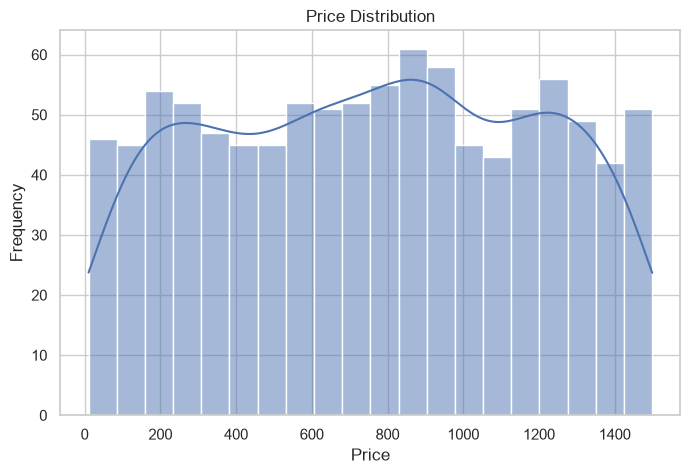

In [ ]:
# ==========================================
# Histogram - Price Distribution
# ==========================================

plt.figure(figsize=(8,5))
sns.histplot(df["price"], bins=20, kde=True)

plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

### Observation

- The histogram shows how product prices are distributed.
- It helps identify whether prices are concentrated in a specific range or spread across multiple ranges.

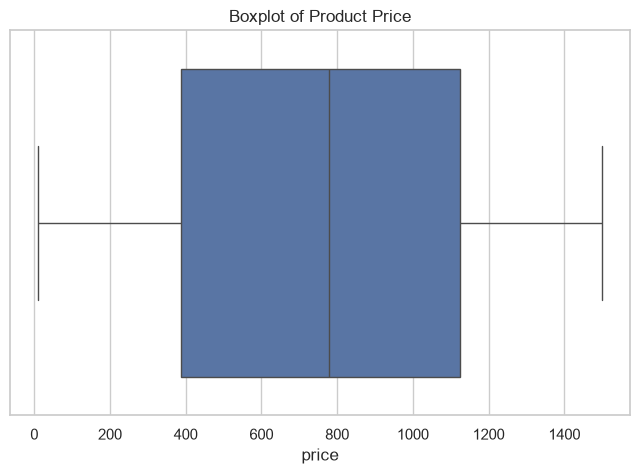

In [ ]:
# ==========================================
# Boxplot - Price
# ==========================================

plt.figure(figsize=(8,5))
sns.boxplot(x=df["price"])

plt.title("Boxplot of Product Price")

plt.show()

### Observation

- The boxplot is used to identify outliers.
- No significant outliers are observed in the price column.

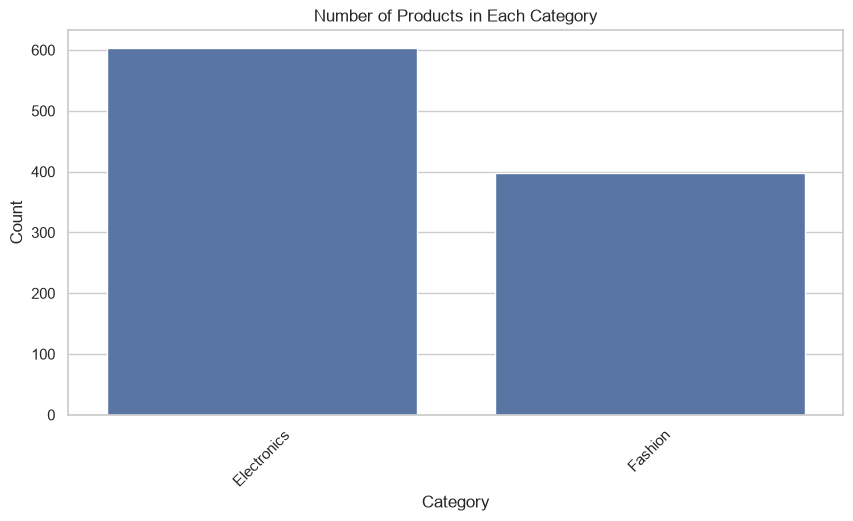

In [ ]:
# ==========================================
# Bar Chart - Product Count by Category
# ==========================================

plt.figure(figsize=(10,5))

sns.countplot(data=df, x="category", order=df["category"].value_counts().index)

plt.title("Number of Products in Each Category")
plt.xlabel("Category")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

### Observation

- Electronics category contains more products than Fashion.
- Around 60% of products belong to Electronics, while 40% belong to Fashion.
- The dataset is dominated by Electronics products.

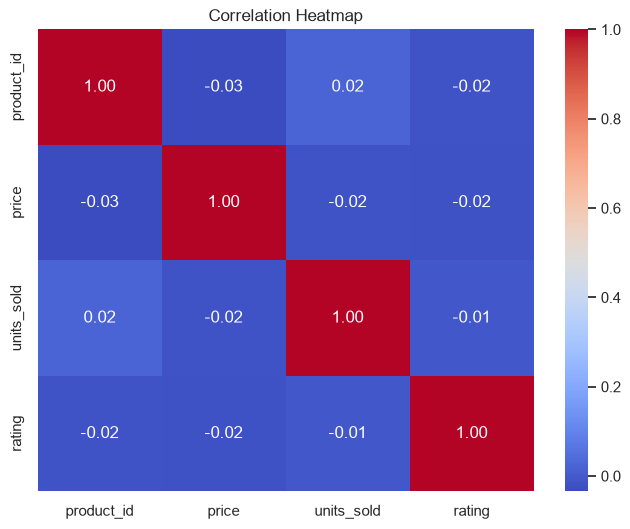

In [ ]:
# ==========================================
# Correlation Heatmap
# ==========================================

plt.figure(figsize=(8,6))

numeric_df = df.select_dtypes(include=["number"])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

### Observation

- The correlation values are very close to zero.
- No strong relationship exists between Price, Units Sold, and Rating.
- The numerical variables are largely independent.

## Line Chart

The dataset does not contain any Date or Time column.
Therefore, a trend-based line chart is not applicable for this dataset.

# Key Insights

### Insight 1
The dataset contains 1000 records and is already clean with no missing values or duplicate rows.

### Insight 2
No outliers were found in the Price column using the IQR method.

### Insight 3
Electronics is the dominant product category with around 60% of all products.

### Insight 4
Product prices are distributed across a wide range without extreme concentration.

### Insight 5
No strong correlation exists between Price, Units Sold, and Rating.

In [ ]:
# Save Cleaned Dataset

df.to_csv("../data/cleaned/ecommerce_dataset_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
